In [1]:
import os
import pathlib
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from notebook_init_utils import bandicoot_check, init_notebook
from python_plot_themes import custom_MOA_palette

root_dir, in_notebook = init_notebook()

profile_base_dir = bandicoot_check(
    pathlib.Path(os.path.expanduser("~/mnt/bandicoot")).resolve(), root_dir
)

In [2]:
platemap_dir = pathlib.Path(f"{profile_base_dir}/data").resolve()
drug_information_file_path = pathlib.Path(
    f"{root_dir}/config/drug_information/drug_information.csv"
).resolve(strict=True)
drug_information = pd.read_csv(drug_information_file_path)

drugs_df = pd.read_csv(drug_information_file_path)

figures_dir = pathlib.Path(f"{profile_base_dir}/figures/drugs_figure/figures").resolve()
figures_dir.mkdir(parents=True, exist_ok=True)

In [3]:
drugs_df["numerical_approval"] = drugs_df["FDA_status"].map(
    {
        "NF1 Approved": 5,
        "Approved": 4,
        "Phase 3": 3,
        "Phase 2": 2,
        "Phase 1/2": 1,
        "Investigational": 0,
        "Withdrawn": 0,
    }
)
drugs_df.sort_values(
    by=["numerical_approval", "Treatment"], ascending=[False, True], inplace=True
)
drugs_df.reset_index(drop=True, inplace=True)
drugs_df

,Treatment,Target,Class,TherapeuticCategories,FDA_status,numerical_approval
0,Mirdametinib,MEK1/2 inhibitor,Small Molecule,Kinase Inhibitor,NF1 Approved,5.0
1,Selumetinib,MEK1/2 inhibitor,Small Molecule,Kinase Inhibitor,NF1 Approved,5.0
2,Binimetinib,MEK1/2 inhibitor,Small Molecule,Kinase Inhibitor,Approved,4.0
3,Cabozantinib,receptor tyrosine kinase inhibitor,Small Molecule,Kinase Inhibitor,Approved,4.0
4,Digoxin,Na+/K+ pump inhibitor,Small Molecule,Cardiac Glycosides,Approved,4.0
5,Everolimus,mTOR inhibitor,Small Molecule,Kinase Inhibitor,Approved,4.0
6,Imatinib,tyrosine kinase inhibitor,Small Molecule,Kinase Inhibitor,Approved,4.0
7,Ketotifen,histamine H1 receptor antagonist,Small Molecule,Anti-Allergic Agents,Approved,4.0
8,Nilotinib,tyrosine kinase inhibitor,Small Molecule,Investigational,Approved,4.0
9,Onalespib,HSP90 inhibitor,Small Molecule,Investigational,Approved,4.0


In [4]:
# order the dataframe by Target
drugs_df.sort_values(
    by=["numerical_approval", "Target", "Treatment"],
    ascending=[False, False, True],
    inplace=True,
)

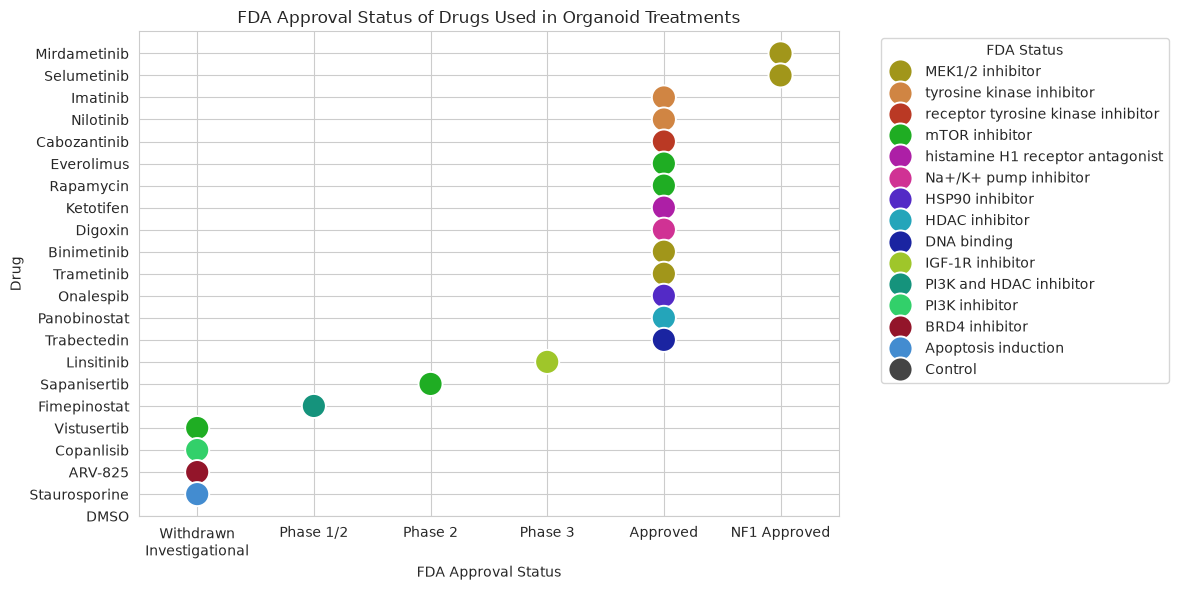

In [5]:
# plot the drug and the approval status as graph
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")
sns.scatterplot(
    data=drugs_df,
    x="numerical_approval",
    y="Treatment",
    hue="Target",
    palette=custom_MOA_palette,
    s=300,
)
plt.xticks(
    ticks=[0, 1, 2, 3, 4, 5],
    labels=[
        "Withdrawn\nInvestigational",
        "Phase 1/2",
        "Phase 2",
        "Phase 3",
        "Approved",
        "NF1 Approved",
    ],
)
plt.xlim(-0.5, 5.5)
plt.xlabel("FDA Approval Status")
plt.ylabel("Drug")
plt.title("FDA Approval Status of Drugs Used in Organoid Treatments")
plt.legend(title="FDA Status", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig(figures_dir / "drug_fda_approval_status.png", dpi=600)
plt.show()